# NMF with multiple seeds

Run the setup cells from the repository root or `MF`, then run any method
cells you want, in any order. Each method cell runs its seeds in parallel.
Every method uses the same data and starting point for each seed.

Rerunning a method replaces only its own results. After adding or rerunning
a method, rerun the plotting section from **Prepare plots**.
After changing solver settings, rerun Settings and only the desired method
cells. To change the problem data, objective weights, initialization or seeds,
start a new experiment with **Initialize results**, which clears the previous
experiment. Save a snapshot first if you want to retain it. Saved plot
outputs below show the previous full run until you rerun them.

Before closing the kernel, run **Save raw results now**. To replot after a
restart, run the imports and settings cells, **Reload saved results**, then
the plotting section. Skip **Initialize results** and the solver cells.

Install in the notebook's Python environment if needed:
```python
%pip install numpy scipy matplotlib pandas "joblib>=1.3,<2" threadpoolctl galahad-optrove==5.5.3
```

For `U` of shape `(m, r)` and `V` of shape `(r, n)`, minimize
$$F(U,V)=\tfrac12\|UV-M_{\mathrm{obs}}\|_F^2
 +\tfrac\alpha2(\|U\|_F^2+\|V\|_F^2)
 +\tfrac\beta2(\|(-U)_+\|_F^2+\|(-V)_+\|_F^2).$$
Negative entries are penalized. The data are uniform random factors plus
Gaussian noise; the starting factors are Gaussian.

Reference: [arXiv:2602.08069v1](https://arxiv.org/abs/2602.08069v1),
Section 5.2 / Appendix E.2, Algorithm 1 and subproblem (2). The paper's objective
is equation (28); this notebook uses the weights above. Current settings and
supplementary comparisons differ from the paper, so this is not an exact figure reproduction.

| Paper figure | History quantity |
| --- | --- |
| 3: nonnegativity violation | `penalty` |
| 4: gradient norm | `grad_norm` |
| 6: objective residual | `func` minus the plotting reference |

The plots show a representative seed and arithmetic means with terminal values
retained, with independent method selections and axis limits for each figure.
The final Figure 8 comparison shows actual gradient histories for Gradient
Method, PALM, LeAP-SSN and GLAd-SSN p=0.5 on one shared seed. Separate
single-panel penalty-versus-iteration plots reproduce the Figure 3 and Figure 8
comparison layouts using their own method lists and limits.
Their aggregation rules are described beside each figure.

All two-panel comparisons call `utils_new.plot_figures` directly.
`prepare_mean_histories` only computes the means and display cutoffs.

In [1]:
import sys
from pathlib import Path
from datetime import datetime

sys.dont_write_bytecode = True
MF_DIR = Path.cwd()
if not (MF_DIR / "oracles_mat_fac.py").exists():
    MF_DIR = MF_DIR / "MF"
sys.path.insert(0, str(MF_DIR.resolve()))

%reload_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import json
from utils_new import plot_figures

from joblib import Parallel, delayed, parallel_config, cpu_count
from IPython.display import HTML, display
from time import perf_counter
import importlib.metadata
import platform

%matplotlib inline

# Shared colors from the original multiple-seed figures.
method_colors = {
    "Gradient Method": "#E8601C", "PALM": "pink", "LeAP-SSN": "black",
    "GLAd-SSN, p=0.2": "#9B8AC4", "GLAd-SSN, p=0.4": "#88A5DD",
    "GLAd-SSN, p=0.5": "#8DCBE4", "GLAd-SSN, p=0.6": "#C2E3D2",
    "GLAd-SSN, p=0.8": "#DDECBF", "Cubic Newton": "#A97900",
}

## Settings

- `seeds_to_try`: data and initialization seeds, shared by every method.
- `m, n, r`, `noise`, `alpha, beta`: dimensions, noise and objective weights.
- `initial_factor_std`: Gaussian starting-factor scale.
- `gradient_iterations`, `palm_iterations`, `number_of_iterations`: gradient/PALM/Newton update budgets.
  A PALM iteration includes both block updates; its solver parameter `tol` uses `grad_tol`.
- `grad_tol`: absolute gradient-norm stopping tolerance; `None` disables it.
- `initial_lambda`: initial LeAP/GLAd shift; GLAd scales it with `||g||**p`.
- `lss_*`: inexact linear solve; `gn_exponents`: available GLAd Gauss-Newton variants.
- `cubic_*`: [GLRT cubic baseline](CUBIC_SUBPROBLEM.md), independent of `initial_lambda`.

Every method checks `grad_tol` initially and after accepted updates. `success`
means the gradient target was reached; `iterations_exceeded` means the budget
ran out. Other exits retain their failure status. There is no objective stopping test.
LeAP/GLAd use fresh generalized Hessians; GN variants use approximate curvature.
Cubic uses inexact GLRT solves and accepts `f(x+s) <= f(x)+model_change`, with
cubic term `H_k * ||s||**3 / 6`; rejection doubles `H_k`, acceptance halves it
with floor `1e-5`.

`N_JOBS` is capped by available CPUs and seed count; `THREADS_PER_WORKER`
limits numerical-library threads. Use `N_JOBS=1` for sequential runs.
`SAVE_FIGURES=True` enables the final **Save figures and data** cell, which
exports the arithmetic means and representative-seed figures with their data into one timestamped folder under `parallel_results/`.

The method cells below include GN exponents 0.2 and 0.5. For another GN
exponent, add it to `gn_exponents` and copy a method cell with that name.

Quick check: `(m, n, r) = (6, 4, 2)`, seeds `[549, 498]`, 20 gradient updates
and 5 Newton updates. These are check settings, not the full experiment.

In [2]:
# Original recorded seeds (uncomment for the 20-seed experiment):
seeds_to_try = [549, 498, 483, 33, 528, 989, 465, 344, 150, 861,
                 107, 424, 998, 235, 992, 229, 725, 911, 418, 146]
#seeds_to_try = [549, 498, 483, 33, 528, 989]

# Data and objective
m, n, r = 200, 100, 12

#m, n, r = 50, 25, 4

noise = 0.2
#alpha, beta = 5.0, 200.0
alpha, beta = 2.0, 200.0

initial_factor_std = 1.0 

# Iteration budgets and regularization
gradient_iterations = 80000
palm_iterations = 150000  # Full U/V sweeps; budget used in the old PALM notebook.
number_of_iterations = 4000
grad_tol = 1e-8  # Absolute outer gradient norm; None disables this tolerance.
initial_lambda = 10.0
lss_method = "minres"  # SciPy MINRES; GLRT keeps its compiled GALAHAD backend.
lss_tol = 1e-7
lss_maxiters = 800
gn_exponents = [0.2, 0.5]       # Additional exact/Gauss-Newton comparisons

# Additional nonconvex cubic baseline (independent of initial_lambda)
cubic_initial_H = 10.0
cubic_subproblem_tol = 1e-7  # Model-gradient residual relative to ||g||
cubic_glrt_max_iter = 40000  # Per-trial cap.
cubic_max_backtracks = 200

# Plotting and optional export
plot_threshold = 1e-8
SAVE_FIGURES = True

print("Trying seeds:", seeds_to_try)

# Parallel execution: choose multiple seeds above to use multiple workers.
N_JOBS = 6  # 1 for sequential execution.
THREADS_PER_WORKER = 1


Trying seeds: [549, 498, 483, 33, 528, 989, 465, 344, 150, 861, 107, 424, 998, 235, 992, 229, 725, 911, 418, 146]


## Run one method for one seed

This worker recreates the data and starting factors from the seed, then calls
one existing solver. The random draw order and solver options are unchanged.


In [3]:
def run_one_seed(seed, solver_name, options, settings, mf_directory, threads=1):
    """Recreate one seeded problem and run the selected solver."""
    import os
    import sys
    from time import perf_counter
    sys.dont_write_bytecode = True
    if mf_directory not in sys.path:
        sys.path.insert(0, mf_directory)
    import numpy as np
    from threadpoolctl import threadpool_limits, threadpool_info
    import methods
    from oracles_mat_fac import PositiveMatrixFactorization
    from galahad import glrt  # Load native libraries before setting thread limits.

    seed_started = perf_counter()
    with threadpool_limits(limits=threads):
        m, n, r = settings["m"], settings["n"], settings["r"]
        rng = np.random.RandomState(seed)
        U_true = rng.rand(m, r)
        V_true = rng.rand(n, r).T
        M_obs = U_true @ V_true + settings["noise"] * rng.randn(m, n)

        # Preserve the original draw order and the (r, n) layout of V.
        initial_values = settings["initial_factor_std"] * rng.randn(m*r + n*r)
        U_0 = initial_values[:m*r].reshape(m, r)
        V_0 = initial_values[m*r:].reshape(n, r).T
        oracle = PositiveMatrixFactorization(M_obs, r=r, alpha=settings["alpha"], beta=settings["beta"])
        x_0 = oracle.pack(U_0, V_0)

        started = perf_counter()
        _, status, history = getattr(methods, solver_name)(oracle, x_0, **options)
        method_seconds = perf_counter() - started
        cubic = {}
        if solver_name == "cubic_newton_nonconvex_new":
            cubic = {key: np.asarray(history[key]) for key in (
                "hess_vec_calls", "glrt_iterations", "glrt_status",
                "subproblem_relative_residual", "subproblem_calls", "H_k") if key in history}
        return dict(
            seed=int(seed), status=status,
            history={key: np.asarray(history[key]) for key in ("func", "time", "grad_norm", "penalty")},
            cubic=cubic, method_seconds=method_seconds,
            seed_seconds=perf_counter() - seed_started,
            thread_pools=threadpool_info(), pid=os.getpid(),
        )


## Initialize results

Run this once when starting a new experiment. **Rerunning it clears all collected
results.** It fixes the seeds, data dimensions, noise, objective weights and
starting-factor scale so every method solves the same seeded problems.

For later changes to solver controls, rerun Settings and only the desired method
cell. Each method reads its current iteration budget, tolerance and applicable
regularization/subproblem controls. Explicit options in `run_method(...)` take
precedence. Results for other methods remain available.

`experiment_config` and `run_metadata["configuration"]` describe initialization.
The actual settings used by each completed run are recorded in
`run_metadata["methods"][name]["options"]` and `methods_to_run[name]`.
Timing includes parallel dispatch; solver times include shared CPU load.


In [4]:
experiment_config = dict(
    m=m, n=n, r=r, noise=noise, alpha=alpha, beta=beta,
    initial_factor_std=initial_factor_std,
    gradient_iterations=gradient_iterations, palm_iterations=palm_iterations,
    number_of_iterations=number_of_iterations,
    grad_tol=grad_tol, initial_lambda=initial_lambda,
    lss_method=lss_method, lss_tol=lss_tol, lss_maxiters=lss_maxiters,
    gn_exponents=list(gn_exponents), cubic_initial_H=cubic_initial_H,
    cubic_subproblem_tol=cubic_subproblem_tol, cubic_glrt_max_iter=cubic_glrt_max_iter,
    cubic_max_backtracks=cubic_max_backtracks,
)
experiment_seeds = list(seeds_to_try)
plot_keys = ("func", "time", "grad_norm", "penalty")
effective_workers = min(N_JOBS, len(experiment_seeds), max(1, cpu_count() // THREADS_PER_WORKER))
experiment_threads = THREADS_PER_WORKER

# Solver options are the same as in the original all-method batch.
newton_options = dict(
    n_iters=experiment_config["number_of_iterations"], grad_tol=experiment_config["grad_tol"],
    H_0=experiment_config["initial_lambda"], warnings=False,
    lss_tol=experiment_config["lss_tol"], lss_maxiters=experiment_config["lss_maxiters"],
    lss_method=experiment_config["lss_method"], use_gauss_newton=False,
)
methods_to_run = {
    "Gradient Method": ("gradient_method", dict(
        max_iter=experiment_config["gradient_iterations"], grad_tol=experiment_config["grad_tol"], warnings=False)),
    "PALM": ("alternating_gradient_method", dict(
        max_iter=experiment_config["palm_iterations"], tol=experiment_config["grad_tol"],
        L_u0=None, L_v0=None, line_search=True, L_min=1e-12, warnings=False)),
    "LeAP-SSN": ("mf_leapssn", newton_options),
}
for p in (0.2, 0.4, 0.5, 0.6, 0.8):
    methods_to_run[f"GLAd-SSN, p={p:g}"] = ("mf_gladssn", dict(newton_options, p=p))
methods_to_run["Cubic Newton"] = ("cubic_newton_nonconvex_new", dict(
    n_iters=experiment_config["number_of_iterations"], grad_tol=experiment_config["grad_tol"],
    H_0=experiment_config["cubic_initial_H"], subproblem_tol=experiment_config["cubic_subproblem_tol"],
    glrt_max_iter=experiment_config["cubic_glrt_max_iter"],
    max_backtracks=experiment_config["cubic_max_backtracks"], warnings=False,
))
for name in ["LeAP-SSN"] + [f"GLAd-SSN, p={p:g}" for p in experiment_config["gn_exponents"]]:
    solver, options = methods_to_run[name]
    methods_to_run[f"{name} (GN)"] = (solver, dict(options, use_gauss_newton=True))

run_metadata = dict(
    initialized_at=datetime.now().astimezone().isoformat(),
    python=platform.python_version(), platform=platform.platform(), processor=platform.processor(),
    packages={name: importlib.metadata.version(name) for name in
              ("numpy", "scipy", "matplotlib", "joblib", "threadpoolctl", "galahad-optrove")},
    precision="float64", seeds=[int(seed) for seed in seeds_to_try],
    configuration=dict(experiment_config), requested_workers=N_JOBS,
    effective_workers=effective_workers, threads_per_worker=THREADS_PER_WORKER, methods={},
)
all_seeds_histories = {seed: {} for seed in experiment_seeds}
all_seeds_statuses = {seed: {} for seed in experiment_seeds}
all_seeds_timing = {seed: {} for seed in experiment_seeds}
all_seeds_cubic_diagnostics = {}
print(f"Results reset. Using {effective_workers} workers, {experiment_threads} thread(s) each.")


Results reset. Using 6 workers, 1 thread(s) each.


## Reload saved results (optional)

For plotting after a restart, run the imports and settings cells, set the path
below, then run this cell and continue at **Prepare plots**.
Skip **Initialize results** and all method execution cells: the snapshot restores
the recorded configuration, seeds, method options, histories, statuses, timings
and cubic diagnostics. Later plotting changes do not require new solver runs.

Paths may be absolute or relative to `MF/`. Use a `results.pkl.gz` created by this
notebook (older uncompressed `results.pkl` snapshots also load). PDF figures
and `arithmetic_mean.json` do not contain per-seed histories.
Leave the path as `None` when starting a new experiment. Only load trusted snapshots.


In [5]:
from experiment_results import load_experiment_snapshot

RESULTS_TO_LOAD = None  # e.g. "parallel_results/raw_20261104_.../results.pkl.gz"
if RESULTS_TO_LOAD is not None:
    results_path = Path(RESULTS_TO_LOAD)
    if not results_path.is_absolute():
        results_path = MF_DIR / results_path
    globals().update(load_experiment_snapshot(results_path))
    print("Restored recorded results from", results_path)
    print("Seeds:", experiment_seeds)
    print("Continue at 'Means over common iterations'; skip initialization and solver cells.")


## Run selected methods

Run any method cell below, in any order. Each call runs its seeds in parallel
from the same seeded starting points and replaces only that method's results.
It does not continue from previous terminal iterates. Other methods' histories,
statuses, timings and settings are retained.

To change solver controls, edit and rerun Settings, then rerun only the desired
method cell. The controls are read at call time:

- Gradient descent: `gradient_iterations`, `grad_tol`.
- LeAP/GLAd, including GN: `number_of_iterations`, `grad_tol`, `initial_lambda`,
  `lss_method`, `lss_tol`, `lss_maxiters`.
- Cubic Newton: `number_of_iterations`, `grad_tol`, `cubic_initial_H`,
  `cubic_subproblem_tol`, `cubic_glrt_max_iter`, `cubic_max_backtracks`.

You can also give a method explicit solver options, without changing Settings:
```python
run_method("LeAP-SSN", n_iters=5000, lss_tol=1e-8)
run_method("Cubic Newton", glrt_max_iter=12000, subproblem_tol=1e-8)
```
These override the current Settings for that call. Reruns replace the same method's
previous results; save a snapshot first if you want to keep both versions.
Changing data, objective weights, initialization or seeds requires a new experiment.
A mismatch with the initialized problem raises an error instead of mixing problems.

Each run prints its effective iteration budget and reports recorded updates per
seed. `iterations_exceeded` means the budget ran out; check the final gradient.
After changing results, rerun plotting from **Prepare plots**, then
save. The iteration-panel zoom and common gradient display target are independent
of the per-method solver controls; the latter defaults to the initialized `grad_tol`.

Results stay in kernel memory until **Save raw results now** or the final figure
export writes a `results.pkl.gz` snapshot. Interrupted or failed calls do not
replace previous results or recorded options. Joblib manages the worker pool;
errors propagate.

PALM uses the same independent rerun workflow: change `palm_iterations` in
Settings or pass `run_method("PALM", max_iter=..., tol=...)`. Its per-method
metadata records the actual budget, tolerance and block-search options.


In [6]:
def run_method(name, **option_overrides):
    """Use current solver controls on the fixed experiment; replace one method."""
    import inspect
    import methods

    current_problem = dict(m=m, n=n, r=r, noise=noise, alpha=alpha, beta=beta,
                           initial_factor_std=initial_factor_std)
    changed_problem = [key for key, value in current_problem.items()
                       if value != experiment_config[key]]
    if list(seeds_to_try) != experiment_seeds:
        changed_problem.append("seeds_to_try")
    if changed_problem:
        raise ValueError(
            f"Problem settings changed: {changed_problem}. Restore them to rerun a method "
            "on this experiment, or save your results and initialize a new experiment.")

    # Older snapshots can acquire PALM without clearing/reinitializing other results.
    if name == "PALM" and name not in methods_to_run:
        solver_name, saved_options = "alternating_gradient_method", dict(
            L_u0=None, L_v0=None, line_search=True, L_min=1e-12, warnings=False)
    else:
        solver_name, saved_options = methods_to_run[name]
    allowed_options = set(inspect.signature(getattr(methods, solver_name)).parameters) - {"oracle", "x_0", "z_0"}
    unknown_options = option_overrides.keys() - allowed_options
    if unknown_options:
        raise ValueError(f"Unknown options for {name}: {sorted(unknown_options)}")
    options = dict(saved_options)
    if solver_name == "gradient_method":
        options.update(max_iter=gradient_iterations, grad_tol=grad_tol)
    elif solver_name == "alternating_gradient_method":
        options.update(max_iter=palm_iterations, tol=grad_tol)
    elif solver_name in ("mf_leapssn", "mf_gladssn"):
        options.update(n_iters=number_of_iterations, grad_tol=grad_tol, H_0=initial_lambda,
                       lss_method=lss_method, lss_tol=lss_tol, lss_maxiters=lss_maxiters)
    elif solver_name == "cubic_newton_nonconvex_new":
        options.update(n_iters=number_of_iterations, grad_tol=grad_tol, H_0=cubic_initial_H,
                       subproblem_tol=cubic_subproblem_tol, glrt_max_iter=cubic_glrt_max_iter,
                       max_backtracks=cubic_max_backtracks)
    options.update(option_overrides)  # Explicit per-method choices take precedence.
    if options.get("trace", True) is False:
        raise ValueError("trace=False is not supported: this notebook needs histories for plotting.")
    iteration_key = "max_iter" if solver_name in ("gradient_method", "alternating_gradient_method") else "n_iters"
    budget = options[iteration_key]
    if isinstance(budget, (bool, np.bool_)) or not isinstance(budget, (int, np.integer)) or budget < 0:
        raise ValueError("The iteration budget must be a nonnegative integer.")
    options[iteration_key] = int(budget)
    started_at = datetime.now().astimezone().isoformat()
    started = perf_counter()
    print(f"{name}: running {len(experiment_seeds)} seeds on {effective_workers} workers; "
          f"iteration budget={budget:,}...")
    with parallel_config(backend="loky", inner_max_num_threads=experiment_threads):
        results = Parallel(n_jobs=effective_workers)(
            delayed(run_one_seed)(seed, solver_name, options, experiment_config,
                                  str(MF_DIR.resolve()), experiment_threads)
            for seed in experiment_seeds
        )
    elapsed = perf_counter() - started

    # Store the method only after all its seeds have finished.
    for result in results:
        seed = result["seed"]
        all_seeds_histories[seed][name] = result["history"]
        all_seeds_statuses[seed][name] = result["status"]
        all_seeds_timing[seed][name] = {key: result[key] for key in
            ("method_seconds", "seed_seconds", "thread_pools", "pid")}
        if name == "Cubic Newton":
            all_seeds_cubic_diagnostics[seed] = result["cubic"]
    methods_to_run[name] = (solver_name, dict(options))
    # Keep initialization settings separate from each method's executed options.
    run_metadata["methods"][name] = dict(
        started_at=started_at, elapsed_seconds=elapsed, solver=solver_name, options=dict(options))
    print(f"{name}: all seeds finished in {elapsed:.1f} s.")
    display(pd.DataFrame([
        dict(seed=result["seed"], status=result["status"],
             iterations=len(result["history"]["time"]) - 1,
             gradient=result["history"]["grad_norm"][-1], seconds=result["method_seconds"])
        for result in results
    ]))


### Gradient Method

Reads the current `gradient_iterations`; increase it in Settings and rerun only
this method. Other methods have the same independent rerun behavior described above.


In [32]:
# Reread the current budget without resetting other methods. This reruns from x_0.
run_method("Gradient Method", max_iter=gradient_iterations*4)


Gradient Method: running 20 seeds on 6 workers; iteration budget=320,000...
Gradient Method: all seeds finished in 634.2 s.


,seed,status,iterations,gradient,seconds
0,549,iterations_exceeded,320000,0.018070,153.822355
1,498,iterations_exceeded,320000,0.009691,151.913661
2,483,iterations_exceeded,320000,0.003436,151.188956
3,33,iterations_exceeded,320000,0.002048,154.285972
4,528,iterations_exceeded,320000,0.001136,146.950253
5,989,iterations_exceeded,320000,0.008751,145.667007
6,465,iterations_exceeded,320000,0.002152,157.959248
7,344,iterations_exceeded,320000,0.012198,159.050475
8,150,iterations_exceeded,320000,0.003904,158.223569
9,861,iterations_exceeded,320000,0.003227,155.710955


### PALM

Runs the existing `methods.alternating_gradient_method` for each initialized seed.
One iteration is a U update followed by a V update, each with its existing
backtracking search. Initial block constants use spectral estimates (`L_u0=None`,
`L_v0=None`); the solver implementation is unchanged. Like the other methods,
this cell replaces only PALM's results and reads the current `palm_iterations`.
The notebook's `grad_tol` maps to the solver's `tol` argument.

For a kernel or snapshot created before PALM was added, rerun **imports**,
**Settings** and the `run_method` definition, then this cell. Do not rerun
**Initialize results**: PALM registers itself while preserving other methods.
Keep the current problem settings/seeds consistent with the loaded experiment.
To reproduce the old PALM notebook's budget-only stopping, pass `tol=None`;
otherwise the common `grad_tol` applies. This restarts PALM from the original
seeded initialization, not from its previous terminal iterate.


In [8]:
run_method("PALM", max_iter=palm_iterations)
# Optional overrides (edit/uncomment instead of the call above):
# run_method("PALM", max_iter=1500000, tol=None, L_u0=None, L_v0=None, line_search=True)


PALM: running 20 seeds on 6 workers; iteration budget=150,000...
PALM: all seeds finished in 723.2 s.


,seed,status,iterations,gradient,seconds
0,549,iterations_exceeded,150000,0.010843,209.091344
1,498,iterations_exceeded,150000,0.004297,208.010718
2,483,iterations_exceeded,150000,0.003017,209.022667
3,33,iterations_exceeded,150000,0.006101,209.658790
4,528,iterations_exceeded,150000,0.003780,209.102630
5,989,iterations_exceeded,150000,0.004954,208.730377
6,465,iterations_exceeded,150000,0.007183,205.738814
7,344,iterations_exceeded,150000,0.001077,207.729448
8,150,iterations_exceeded,150000,0.009359,207.077894
9,861,iterations_exceeded,150000,0.003251,206.646788


### LeAP-SSN


In [9]:
run_method("LeAP-SSN")


LeAP-SSN: running 20 seeds on 6 workers; iteration budget=4,000...
LeAP-SSN: all seeds finished in 311.5 s.


,seed,status,iterations,gradient,seconds
0,549,"success, 1912 iters",1912,6.445399e-09,111.248923
1,498,"success, 708 iters",708,2.197083e-09,40.193604
2,483,"numerical_stagnation, 3223 iters",3223,1.290543e-08,217.393660
3,33,"success, 718 iters",718,3.659642e-09,40.946500
4,528,"success, 1391 iters",1391,5.273482e-09,82.496757
5,989,"success, 1407 iters",1407,7.254132e-09,80.984631
6,465,"success, 1165 iters",1165,4.876948e-09,66.092289
7,344,"success, 518 iters",518,6.543122e-09,25.280341
8,150,"success, 856 iters",856,8.494752e-09,44.758147
9,861,"numerical_stagnation, 1038 iters",1038,1.411018e-07,65.374266


### GLAd-SSN, p=0.2


In [10]:
run_method("GLAd-SSN, p=0.2")


GLAd-SSN, p=0.2: running 20 seeds on 6 workers; iteration budget=4,000...
GLAd-SSN, p=0.2: all seeds finished in 328.0 s.


,seed,status,iterations,gradient,seconds
0,549,"numerical_stagnation, 899 iters",899,5.448678e-08,48.771870
1,498,"numerical_stagnation, 1420 iters",1420,2.302030e-08,88.338093
2,483,"numerical_stagnation, 648 iters",648,1.787630e-08,36.494614
3,33,"numerical_stagnation, 855 iters",855,1.104655e-08,48.275898
4,528,"numerical_stagnation, 1360 iters",1360,2.557465e-08,85.470388
5,989,"numerical_stagnation, 1203 iters",1203,1.630673e-08,72.016289
6,465,"numerical_stagnation, 1297 iters",1297,1.671113e-08,85.582221
7,344,"success, 594 iters",594,9.163856e-09,35.024082
8,150,"success, 2609 iters",2609,8.090808e-09,164.188023
9,861,"numerical_stagnation, 2733 iters",2733,1.350992e-08,176.185554


### GLAd-SSN, p=0.4


In [11]:
run_method("GLAd-SSN, p=0.4")


GLAd-SSN, p=0.4: running 20 seeds on 6 workers; iteration budget=4,000...
GLAd-SSN, p=0.4: all seeds finished in 374.2 s.


,seed,status,iterations,gradient,seconds
0,549,"success, 2536 iters",2536,6.330915e-09,133.196781
1,498,"success, 3071 iters",3071,7.321014e-09,175.532085
2,483,"numerical_stagnation, 1857 iters",1857,1.294060e-08,101.872628
3,33,"success, 937 iters",937,7.306800e-09,50.230157
4,528,"numerical_stagnation, 1629 iters",1629,1.411425e-08,88.320916
5,989,"success, 1502 iters",1502,9.607574e-09,80.108172
6,465,"success, 1289 iters",1289,7.774942e-09,64.791765
7,344,"success, 483 iters",483,1.306060e-09,24.733576
8,150,"success, 1272 iters",1272,3.598702e-09,66.162421
9,861,"numerical_stagnation, 2103 iters",2103,2.135583e-08,129.638051


### GLAd-SSN, p=0.5


In [12]:
run_method("GLAd-SSN, p=0.5")


GLAd-SSN, p=0.5: running 20 seeds on 6 workers; iteration budget=4,000...
GLAd-SSN, p=0.5: all seeds finished in 394.6 s.


,seed,status,iterations,gradient,seconds
0,549,"success, 2873 iters",2873,1.616837e-09,154.155970
1,498,"success, 931 iters",931,5.845749e-09,42.772527
2,483,"success, 2114 iters",2114,3.457214e-09,112.965688
3,33,"numerical_stagnation, 851 iters",851,3.772570e-08,37.354884
4,528,"success, 1839 iters",1839,9.153412e-09,95.055038
5,989,"numerical_stagnation, 1219 iters",1219,3.587476e-08,54.186852
6,465,"numerical_stagnation, 1080 iters",1080,1.103409e-08,58.852757
7,344,"numerical_stagnation, 2026 iters",2026,1.401717e-08,123.054471
8,150,"success, 2320 iters",2320,9.036600e-09,135.381258
9,861,"numerical_stagnation, 3628 iters",3628,1.640161e-08,238.568732


### GLAd-SSN, p=0.6


In [13]:
run_method("GLAd-SSN, p=0.6")


GLAd-SSN, p=0.6: running 20 seeds on 6 workers; iteration budget=4,000...
GLAd-SSN, p=0.6: all seeds finished in 353.1 s.


,seed,status,iterations,gradient,seconds
0,549,"success, 2187 iters",2187,9.113154e-09,132.460882
1,498,"numerical_stagnation, 1375 iters",1375,2.102199e-08,90.646160
2,483,"numerical_stagnation, 2137 iters",2137,1.152251e-07,132.947081
3,33,"success, 2135 iters",2135,8.827060e-09,127.675578
4,528,"success, 787 iters",787,5.865867e-09,45.787925
5,989,"numerical_stagnation, 1214 iters",1214,1.040062e-08,74.958733
6,465,"success, 1112 iters",1112,2.656866e-09,69.841507
7,344,"success, 1357 iters",1357,1.698419e-09,76.690937
8,150,"numerical_stagnation, 894 iters",894,1.245843e-08,51.374695
9,861,"numerical_stagnation, 755 iters",755,1.293554e-07,40.431734


### GLAd-SSN, p=0.8


In [14]:
run_method("GLAd-SSN, p=0.8")


GLAd-SSN, p=0.8: running 20 seeds on 6 workers; iteration budget=4,000...
GLAd-SSN, p=0.8: all seeds finished in 357.9 s.


,seed,status,iterations,gradient,seconds
0,549,"success, 2276 iters",2276,3.219333e-09,145.103536
1,498,"success, 1354 iters",1354,8.939641e-09,84.658947
2,483,"success, 2799 iters",2799,9.665213e-09,203.050436
3,33,"success, 1117 iters",1117,7.456989e-09,63.261849
4,528,"numerical_stagnation, 1073 iters",1073,1.523020e-08,70.267369
5,989,"numerical_stagnation, 879 iters",879,2.865894e-08,51.994201
6,465,"success, 1322 iters",1322,7.731332e-09,87.939616
7,344,"numerical_stagnation, 611 iters",611,1.188067e-08,36.819914
8,150,"success, 975 iters",975,6.119698e-09,62.931705
9,861,"numerical_stagnation, 1525 iters",1525,1.341779e-08,118.493851


### Cubic Newton


In [15]:
run_method("Cubic Newton",glrt_max_iter=cubic_glrt_max_iter)

Cubic Newton: running 20 seeds on 6 workers; iteration budget=4,000...
Cubic Newton: all seeds finished in 315.0 s.


,seed,status,iterations,gradient,seconds
0,549,"success, 135 iters",135,3.402991e-12,38.772694
1,498,"success, 197 iters",197,2.731342e-13,51.092104
2,483,"success, 208 iters",208,4.919844e-13,79.259998
3,33,"success, 167 iters",167,2.773606e-13,58.964908
4,528,"success, 158 iters",158,2.836596e-11,52.803876
5,989,"success, 267 iters",267,9.863977e-10,91.450901
6,465,"success, 201 iters",201,3.974457e-09,97.218612
7,344,"success, 324 iters",324,3.700274e-10,126.619202
8,150,"success, 236 iters",236,2.790110e-13,82.087274
9,861,"success, 108 iters",108,2.488310e-10,36.999712


### LeAP-SSN (GN)


In [16]:
run_method("LeAP-SSN (GN)")


LeAP-SSN (GN): running 20 seeds on 6 workers; iteration budget=4,000...
LeAP-SSN (GN): all seeds finished in 361.6 s.


,seed,status,iterations,gradient,seconds
0,549,iterations_exceeded,4000,0.006862,96.874422
1,498,iterations_exceeded,4000,0.005762,100.367260
2,483,iterations_exceeded,4000,0.007008,100.714089
3,33,iterations_exceeded,4000,0.002653,95.344479
4,528,iterations_exceeded,4000,0.002789,97.033854
5,989,iterations_exceeded,4000,0.001341,95.816117
6,465,iterations_exceeded,4000,0.002727,105.758076
7,344,iterations_exceeded,4000,0.002086,106.556189
8,150,iterations_exceeded,4000,0.001623,103.570633
9,861,iterations_exceeded,4000,0.003156,98.836058


### GLAd-SSN, p=0.2 (GN)


In [17]:
run_method("GLAd-SSN, p=0.2 (GN)")


GLAd-SSN, p=0.2 (GN): running 20 seeds on 6 workers; iteration budget=4,000...
GLAd-SSN, p=0.2 (GN): all seeds finished in 309.2 s.


,seed,status,iterations,gradient,seconds
0,549,iterations_exceeded,4000,0.003479,86.955177
1,498,iterations_exceeded,4000,0.004170,91.347285
2,483,iterations_exceeded,4000,0.003449,80.056826
3,33,iterations_exceeded,4000,0.002994,80.698481
4,528,iterations_exceeded,4000,0.002265,88.273649
5,989,iterations_exceeded,4000,0.005135,80.966704
6,465,iterations_exceeded,4000,0.004835,96.344883
7,344,iterations_exceeded,4000,0.017452,99.093764
8,150,iterations_exceeded,4000,0.004632,95.930433
9,861,iterations_exceeded,4000,0.004401,83.935604


### GLAd-SSN, p=0.5 (GN)


In [18]:
run_method("GLAd-SSN, p=0.5 (GN)")


GLAd-SSN, p=0.5 (GN): running 20 seeds on 6 workers; iteration budget=4,000...
GLAd-SSN, p=0.5 (GN): all seeds finished in 289.3 s.


,seed,status,iterations,gradient,seconds
0,549,iterations_exceeded,4000,0.008326,73.713847
1,498,iterations_exceeded,4000,0.003315,82.085906
2,483,iterations_exceeded,4000,0.004528,78.799299
3,33,iterations_exceeded,4000,0.006288,76.951007
4,528,iterations_exceeded,4000,0.006792,74.951108
5,989,iterations_exceeded,4000,0.005651,80.185305
6,465,iterations_exceeded,4000,0.007002,81.201624
7,344,iterations_exceeded,4000,0.007172,81.579100
8,150,iterations_exceeded,4000,0.007968,80.871969
9,861,iterations_exceeded,4000,0.004307,77.650215


## Prepare plots

Run this section again after each new method run. Only methods recorded for
every seed are available. The status table covers all completed methods.
The representative plots use one seed's actual histories; the arithmetic means
use a shared runtime grid and retain stopped runs at their terminal values.

Each plotting section has its own options cell with `methods`, `max_time`
(seconds) and `max_iter` for each figure: `func`, `grad_norm` and `penalty`.
A method list controls only that figure and follows your list order; GN variants
can be listed explicitly. Unknown, incomplete or empty selections raise a clear
error. `None` for a limit shows the full displayed curve range. These are display
controls only: they neither rerun solvers nor truncate the saved raw histories.


In [19]:
completed_methods = [name for name in methods_to_run
                     if all(name in all_seeds_histories[seed] for seed in experiment_seeds)]
assert completed_methods, "Run at least one method cell before plotting."
original_method_names = [name for name in completed_methods if not name.endswith(" (GN)")]
original_method_names = original_method_names or completed_methods

status_table = pd.DataFrame([
    dict(seed=seed, method=name, status=all_seeds_statuses[seed][name],
         gradient=all_seeds_histories[seed][name]["grad_norm"][-1],
         seconds=all_seeds_timing[seed][name]["method_seconds"])
    for seed in experiment_seeds for name in completed_methods
])
display(HTML("<details><summary>Solver results and wall times</summary>" +
             status_table.to_html(index=False, float_format=lambda x: f"{x:.3g}") + "</details>"))

print("Available plot methods:", completed_methods)


seed,method,status,gradient,seconds
549,Gradient Method,iterations_exceeded,0.0121,45.8
549,PALM,iterations_exceeded,0.0108,209
549,LeAP-SSN,"success, 1912 iters",6.45e-09,111
549,"GLAd-SSN, p=0.2","numerical_stagnation, 899 iters",5.45e-08,48.8
549,"GLAd-SSN, p=0.4","success, 2536 iters",6.33e-09,133
549,"GLAd-SSN, p=0.5","success, 2873 iters",1.62e-09,154
549,"GLAd-SSN, p=0.6","success, 2187 iters",9.11e-09,132
549,"GLAd-SSN, p=0.8","success, 2276 iters",3.22e-09,145
549,Cubic Newton,"success, 135 iters",3.4e-12,38.8
549,LeAP-SSN (GN),iterations_exceeded,0.00686,96.9


Available plot methods: ['Gradient Method', 'PALM', 'LeAP-SSN', 'GLAd-SSN, p=0.2', 'GLAd-SSN, p=0.4', 'GLAd-SSN, p=0.5', 'GLAd-SSN, p=0.6', 'GLAd-SSN, p=0.8', 'Cubic Newton', 'LeAP-SSN (GN)', 'GLAd-SSN, p=0.2 (GN)', 'GLAd-SSN, p=0.5 (GN)']


## Paper plot style

The representative-run and arithmetic-mean figures share these settings:
a translucent boxed legend over the panels, the same default method order, colors,
markers, line widths, dashed grid and 10-by-4-inch layout. Titles and footnotes
are omitted from both; the selected seed is reported below and saved in metadata.
Change `paper_linewidth` here to adjust line thickness in both sets of figures.
Rerun this cell and both plotting sections after changing the shared style.

Choose visible methods and axis limits in the options cell directly before each
plotting routine. `paper_method_order` supplies only the default order.


In [33]:
# Shared appearance for representative runs and arithmetic means.
paper_legend_layout = "paper"  # Boxed, translucent legend over the panels.
paper_linewidth = 1.8
paper_marker_spacing = 0.15   # Display spacing; all recorded points are retained.
paper_method_order = ["Gradient Method", "PALM", "Cubic Newton", "LeAP-SSN"]
paper_method_order += [f"GLAd-SSN, p={p:g}" for p in (0.2, 0.4, 0.5, 0.6, 0.8)]
paper_marker_map = dict(zip(paper_method_order, ["None", "None", "*", "s", "^", "D", "x", "v", "h"]))
paper_method_order += [name + " (GN)" for name in paper_method_order
                       if name.startswith(("LeAP", "GLAd"))]
paper_method_colors = dict(method_colors, **{"Cubic Newton": "gold"})


def resolve_plot_options(options, default_methods):
    """Validate one figure's selection without changing any recorded results."""
    requested = options["methods"]
    if requested is not None and not isinstance(requested, (list, tuple)):
        raise ValueError("methods must be a list of method names or None.")
    names = list(default_methods if requested is None else requested)
    if not names or any(not isinstance(name, str) for name in names):
        raise ValueError("Select at least one method by its name.")
    if len(names) != len(set(names)):
        raise ValueError("The methods list contains duplicates.")
    unavailable = [name for name in names if name not in completed_methods]
    if unavailable:
        raise ValueError(f"Methods not recorded for every seed: {unavailable}. "
                         f"Available: {completed_methods}")
    resolved = dict(options, methods=names)
    for key in ("max_time", "max_iter"):
        value = resolved[key]
        if value is not None and (not np.isscalar(value) or not np.isfinite(value) or value <= 0):
            raise ValueError(f"{key} must be a positive number or None.")
    return resolved


## Representative actual run

One shared seed is selected for every method and metric. It is the **medoid**
of first-hit iteration ranks at fixed gradient targets: unreached targets tie
last, method families and targets have equal weight, and the smallest seed
breaks ties. Runtime does not influence selection. This diagnostic rule does
not guarantee typical penalty behavior; it does not replace the all-seed means.
See [Kaufman and Rousseeuw (1987)](https://wis.kuleuven.be/stat/robust/papers/publications-1987/kaufmanrousseeuw-clusteringbymedoids-l1norm-1987.pdf).

Curves are actual recorded values, with no averaging or extension. Method-specific
markers match the arithmetic means; zeros remain visible. The objective reference is the best observed
value among the methods selected for the objective figure, for this seed.
The axis limits in `representative_plot_options` only zoom the view; `None` shows
all updates. An explicit seed override is labelled an example.

The penalty can return above zero as factor entries change sign; only the total
objective is required to decrease. Its axis is linear below
`representative_penalty_zero_scale` (default `1e-5`), then logarithmic. All values
are retained; this scale is independent of the gradient/objective scale.

Selection uses completed families only, so adding methods may change the selected seed.

The final **Save figures and data** cell exports all three representative PDFs
alongside the arithmetic means. `representative_run.json` records the selected
seed (including any override), selection scores/targets, plotted methods,
objective reference, display settings and target/exit summaries. The actual
histories are stored once in the shared `results.pkl.gz`, under
`all_seeds_histories[representative_seed]`, so they can be replotted after a restart.

Edit `representative_plot_options` immediately before the plotting routine:
each of `func`, `grad_norm` and `penalty` accepts its own `methods` list,
`max_time` in seconds and `max_iter`. `methods=None` includes all methods
recorded for every experiment seed, including GN variants, just like the
arithmetic-mean plots. Explicit lists select a subset in your specified order.
A commented example with all eight methods from the old paper Figure 4
is provided in the options cell.
Changing these lists does not change the representative seed; selection still
uses `representative_selection_methods`. Then rerun only the options and plot
cells, followed by **Save figures and data** if desired.


In [53]:
from representative_plots import select_representative_seed, target_summary

# Selection settings: one method per family; runtime does not affect selection.
representative_selection_methods = [
    "Gradient Method", "LeAP-SSN", "GLAd-SSN, p=0.5", "Cubic Newton",
]
representative_selection_methods = [name for name in representative_selection_methods
                                    if name in completed_methods] or original_method_names
representative_gradient_targets = [1e2, 1.0, 1e-2, 1e-4, 1e-6, 1e-8]
representative_seed_override = None  # An explicit seed is labelled "example".
comparison_gradient_target = 1e-6     # Reporting target, not the solver grad_tol.
representative_zero_scale = 1e-8
representative_penalty_zero_scale = 1e-10  # Linear near zero; keeps zero-to-positive rebounds.

representative_selection = select_representative_seed(
    all_seeds_histories, representative_selection_methods, representative_gradient_targets)
representative_seed = (representative_selection["seed"] if representative_seed_override is None
                       else int(representative_seed_override))
representative_label = "Representative" if representative_seed_override is None else "Example"
print(f"{representative_label} seed: {representative_seed}")
if representative_seed_override is None and len(representative_selection["tied_seeds"]) > 1:
    print("Tied medoids:", representative_selection["tied_seeds"], "-- using the smallest seed.")
if not representative_selection["informative"]:
    print("The milestone ranks do not distinguish these seeds; there is no unique typical run.")
selection_scores = pd.DataFrame([
    {"seed": seed, "medoid score": score, "shown": seed == representative_seed}
    for seed, score in representative_selection["scores"].items()
])
display(selection_scores.style.format({"medoid score": "{:.4f}"}))

Representative seed: 107


,seed,medoid score,shown
0,33,0.2920,False
1,107,0.2525,True
2,146,0.2644,False
3,150,0.2528,False
4,229,0.3165,False
5,235,0.2552,False
6,344,0.3145,False
7,418,0.2884,False
8,424,0.2843,False
9,465,0.2687,False


In [47]:
# Edit each figure independently. None selects all completed methods, including GN.
# Explicit lists select only those methods, in the order you specify.
representative_plot_options = {
    "func":      dict(methods=None, max_time=150, max_iter=number_of_iterations),
    "grad_norm": dict(methods=None, max_time=150, max_iter=number_of_iterations),
    "penalty":   dict(methods=None, max_time=150, max_iter=number_of_iterations),
}

# Old paper Figure 4 comparison: uncomment to show its full eight-method set.
representative_plot_options["grad_norm"]["methods"] = [
     "Gradient Method", "Cubic Newton", "LeAP-SSN",
     "GLAd-SSN, p=0.2", "GLAd-SSN, p=0.4", "GLAd-SSN, p=0.5",
     "GLAd-SSN, p=0.6", "GLAd-SSN, p=0.8",
 ]

representative_plot_options["func"]["methods"] = [
     "Gradient Method", "Cubic Newton", "LeAP-SSN",
     "GLAd-SSN, p=0.2", "GLAd-SSN, p=0.4", "GLAd-SSN, p=0.5",
     "GLAd-SSN, p=0.6", "GLAd-SSN, p=0.8",
 ]

representative_plot_options["penalty"]["methods"] = [
     "Gradient Method", "Cubic Newton", "LeAP-SSN",
     "GLAd-SSN, p=0.2", "GLAd-SSN, p=0.4", "GLAd-SSN, p=0.5",
     "GLAd-SSN, p=0.6", "GLAd-SSN, p=0.8",
 ]
# Use "func" or "penalty" instead of "grad_norm" to change another figure.


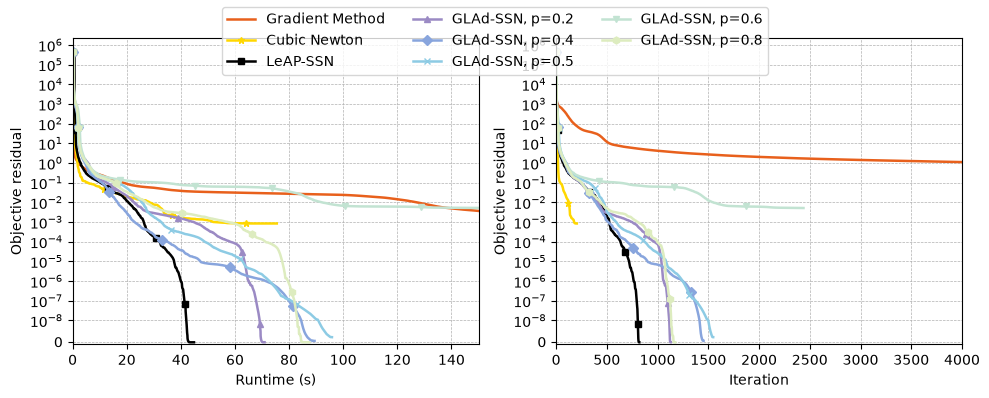

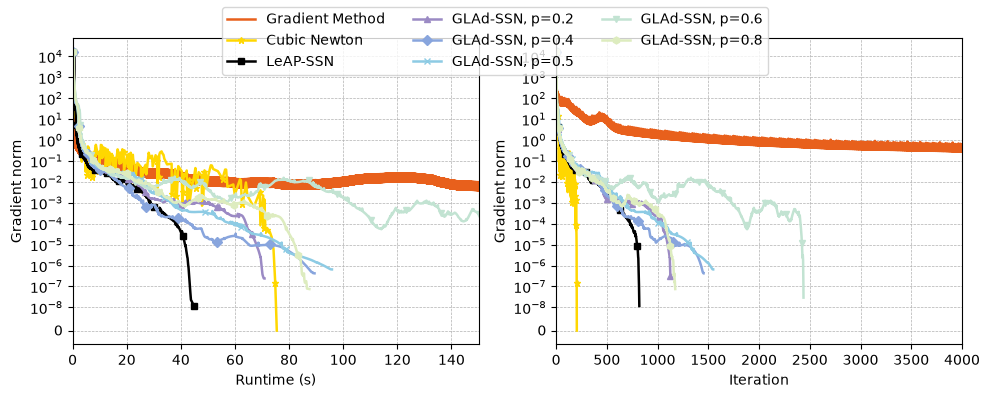

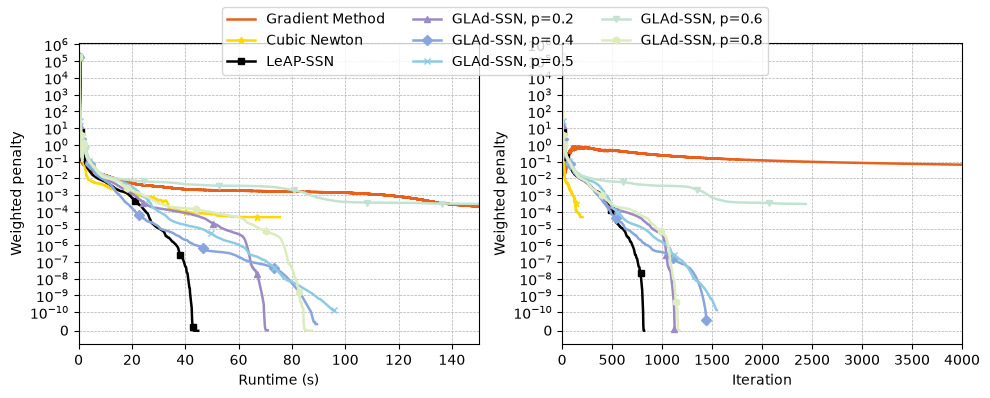

Reporting target: 1e-06; actual solver grad_tol: 1e-08


,method,reached,hit_iteration,hit_time,final_gradient,final_penalty,status
8,Gradient Method,False,--,--,3.670e-03,1.696e-04,iterations_exceeded
9,Cubic Newton,True,203,74.9,1.979e-11,4.818e-05,"success, 204 iters"
10,LeAP-SSN,True,813,42.8,1.161e-08,3.459e-15,"numerical_stagnation, 820 iters"
11,"GLAd-SSN, p=0.2",True,1123,69.9,2.403e-07,2.609e-12,"numerical_stagnation, 1129 iters"
12,"GLAd-SSN, p=0.4",True,1429,86.3,4.237e-07,3.596e-11,"numerical_stagnation, 1453 iters"
13,"GLAd-SSN, p=0.5",True,1518,92.8,6.523e-07,1.330e-10,"numerical_stagnation, 1548 iters"
14,"GLAd-SSN, p=0.6",True,2435,154,2.920e-08,2.947e-04,"numerical_stagnation, 2438 iters"
15,"GLAd-SSN, p=0.8",True,1157,84.6,7.504e-08,2.348e-13,"numerical_stagnation, 1174 iters"


In [54]:
# Each figure uses its own methods and zoom; seed selection stays independent.
representative_defaults = [name for name in paper_method_order if name in completed_methods]
representative_options = {
    measure: resolve_plot_options(options, representative_defaults)
    for measure, options in representative_plot_options.items()
}
representative_plot_methods = list(dict.fromkeys(
    name for options in representative_options.values() for name in options["methods"]))
representative_styles = {
    name: dict(color=paper_method_colors[name.removesuffix(" (GN)")],
               linestyle="--" if name.endswith(" (GN)") else "-")
    for name in representative_plot_methods
}
representative_histories = {
    name: all_seeds_histories[representative_seed][name] for name in representative_plot_methods
}
representative_reference = min(
    np.min(representative_histories[name]["func"])
    for name in representative_options["func"]["methods"]
)
representative_figures = {}
representative_plot_records = {}
for measure, reference, ylabel in [
    ("func", representative_reference, "Objective residual"),
    ("grad_norm", 0, "Gradient norm"),
    ("penalty", 0, "Weighted penalty"),
]:
    options = representative_options[measure]
    names = options["methods"]
    scale = (representative_penalty_zero_scale if measure == "penalty"
             and representative_penalty_zero_scale is not None else representative_zero_scale)
    fig = plot_figures(
        [representative_histories[name] for name in names], names,
        colors=[representative_styles[name]["color"] for name in names],
        linewidths=[paper_linewidth] * len(names),
        linestyles=[representative_styles[name]["linestyle"] for name in names],
        n=experiment_config["n"], m=experiment_config["m"], mu_str=None, xlabel="Runtime (s)",
        f_star=reference, threshold=None, zero_scale=scale,
        max_iter=options["max_iter"], max_time=options["max_time"],
        which_measure_1=measure, which_measure_2=measure, ylabel=ylabel,
        suptitle=None, sharey=True, mark_endpoints=False, verbose=False, note=None,
        legend_layout=paper_legend_layout,
        marker_cycle=[paper_marker_map[name.removesuffix(" (GN)")] for name in names],
        markevery=paper_marker_spacing,
    )
    representative_figures[measure] = fig
    representative_plot_records[measure] = dict(
        options, reference=float(reference), zero_scale=scale,
        styles={name: representative_styles[name] for name in names},
        linewidths=[paper_linewidth] * len(names),
    )
    display(fig)
    plt.close(fig)

representative_target_rows = target_summary(
    all_seeds_histories, representative_plot_methods,
    comparison_gradient_target, all_seeds_statuses)
representative_target_table = pd.DataFrame(representative_target_rows)
print(f"Reporting target: {comparison_gradient_target:g}; actual solver grad_tol: "
      f"{run_metadata['configuration']['grad_tol']}")
display(representative_target_table.loc[
    representative_target_table.seed == representative_seed,
    ["method", "reached", "hit_iteration", "hit_time", "final_gradient", "final_penalty", "status"],
].style.format({"hit_iteration": "{:.0f}", "hit_time": "{:.3g}",
                "final_gradient": "{:.3e}", "final_penalty": "{:.3e}"}, na_rep="--"))

# Freeze the settings with the figures; raw histories live in results.pkl.gz.
representative_record = dict(
    format="parallel-nmf-representative-metadata", version=2,
    seed=int(representative_seed), label=representative_label,
    seed_override=representative_seed_override, selection=representative_selection,
    methods=representative_plot_methods, history_keys=list(plot_keys),
    convention="Actual recorded values for one shared seed; no averaging or extension",
    objective_reference=float(representative_reference),
    reporting_gradient_target=comparison_gradient_target,
    plots=representative_plot_records,
    legend_layout=paper_legend_layout, mark_endpoints=False, threshold=None,
    markers=paper_marker_map, marker_spacing=paper_marker_spacing,
    suptitle=None, note=None,
    target_summary=[row for row in representative_target_rows
                    if row["seed"] == representative_seed],
)


## Arithmetic mean with terminal values retained

The three figures show objective residual, gradient norm and weighted penalty.
Every seed keeps equal weight, including failures. Stopped runs contribute
their actual final value. Runtime uses the latest observation on a shared time
grid; iterations use matching update counts. No interpolation or log averaging.

For a fixed method and $S$ seeds, let $q_{s,j}$ denote the recorded objective
$F_s(x_{s,j})$, gradient norm $\|\nabla F_s(x_{s,j})\|_2$, or weighted penalty
$P_s(x_{s,j})$. Let $t_{s,j}$ be the runtime and $K_s$ the last recorded
iteration, with the initial point at $j=0$. The means are

$$
\bar q_{\mathrm{iter}}(k)
=\frac{1}{S}\sum_{s=1}^{S}q_{s,\min(k,K_s)},
$$

$$
\bar q_{\mathrm{time}}(t)
=\frac{1}{S}\sum_{s=1}^{S}q_{s,j_s(t)},
\qquad
j_s(t)=\max\{j\in\{0,\ldots,K_s\}:t_{s,j}\le t\}.
$$

The shared time grid starts after every run has its first observation.
After seed $s$ ends, it contributes $q_{s,K_s}$; the denominator stays $S$.
For gradients this averages **norms**, not gradient vectors.

The objective panels display $\bar F-F_{\mathrm{ref}}$, where $F_{\mathrm{ref}}$
is the smallest recorded arithmetic mean across the methods selected for the objective figure and both
grids, not a known optimum. Its axis is linear below
`mean_objective_zero_scale` (default `1e-8`), then logarithmic. Objective and
penalty curves end at each method's last recording. Penalty zeros and later rebounds are retained; its axis is
linear below `mean_penalty_zero_scale` (default `1e-5`), then logarithmic.

Gradient curves keep the existing cutoff: all seeds at or below
`mean_gradient_target`, otherwise the last recording. Terminal gradient plateaus
within 0.1% of each seed's final norm are hidden; set
`mean_gradient_flat_tail_rtol=None` to disable this display rule. It does not
certify convergence. Missed gradient targets remain listed below.

The gradient target defaults to the initialized experiment's `grad_tol`. Axis limits
only zoom the view. `arithmetic_mean_summaries` retains the full means and
cutoffs for `func`, `grad_norm` and `penalty`; `mean_gradient_summaries` still
refers to the gradient results. Dashed lines show the recorded GN variants.
The shared **Paper plot style** sets `mean_legend_layout="paper"`, following `utils.plot_for_paper_2` and the original
`plot_matrix_factorization_from_data.ipynb`: a boxed, translucent three-column
legend overlapping the panels, dashed grid, original colors/markers and no
figure title. Set `paper_legend_layout="outside"` for the legend between panels. Markers use
display-distance spacing; all curve data and mean conventions are retained.
Use these arithmetic-mean figures for the paper. The final **Save figures and data**
cell exports all three PDFs and compact plot metadata when `SAVE_FIGURES=True`.

Edit `mean_plot_options` immediately before the plotting routine. Each figure
(`func`, `grad_norm`, `penalty`) has its own `methods`, `max_time` (seconds)
and `max_iter`. `methods=None` includes all completed methods; an explicit
list fixes both the selection and order. Limits of `None` show the full
displayed range. After editing, rerun the options and plot cells; the
representative figures and solver results are unaffected.


In [50]:
# None selects all completed methods, including GN variants, in paper order.
# Each entry controls one two-panel figure; limits only zoom the view.
# Example methods: ["Gradient Method", "LeAP-SSN", "GLAd-SSN, p=0.5"]
mean_plot_options = {
    "func":      dict(methods=None, max_time=180, max_iter=number_of_iterations),
    "grad_norm": dict(methods=None, max_time=180, max_iter=number_of_iterations),
    "penalty":   dict(methods=None, max_time=180, max_iter=number_of_iterations),
}


mean_plot_options["grad_norm"]["methods"] = [
     "Gradient Method", "Cubic Newton", "LeAP-SSN",
     "GLAd-SSN, p=0.2", "GLAd-SSN, p=0.4", "GLAd-SSN, p=0.5",
     "GLAd-SSN, p=0.6", "GLAd-SSN, p=0.8",
 ]

mean_plot_options["func"]["methods"] = [
     "Gradient Method", "Cubic Newton", "LeAP-SSN",
     "GLAd-SSN, p=0.2", "GLAd-SSN, p=0.4", "GLAd-SSN, p=0.5",
     "GLAd-SSN, p=0.6", "GLAd-SSN, p=0.8",
 ]

mean_plot_options["penalty"]["methods"] = [
     "Gradient Method", "Cubic Newton", "LeAP-SSN",
     "GLAd-SSN, p=0.2", "GLAd-SSN, p=0.4", "GLAd-SSN, p=0.5",
     "GLAd-SSN, p=0.6", "GLAd-SSN, p=0.8",
 ]



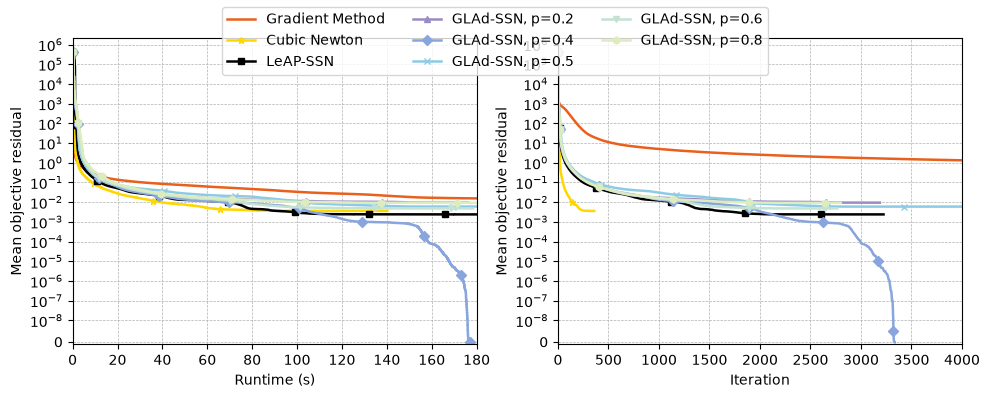

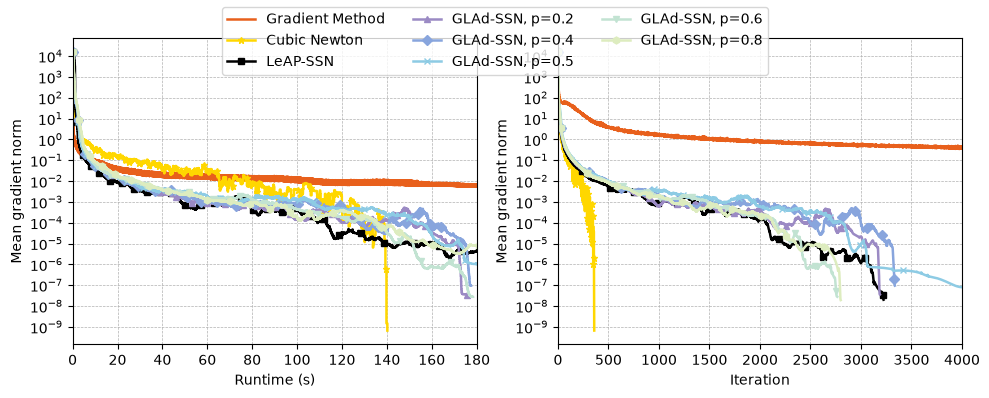

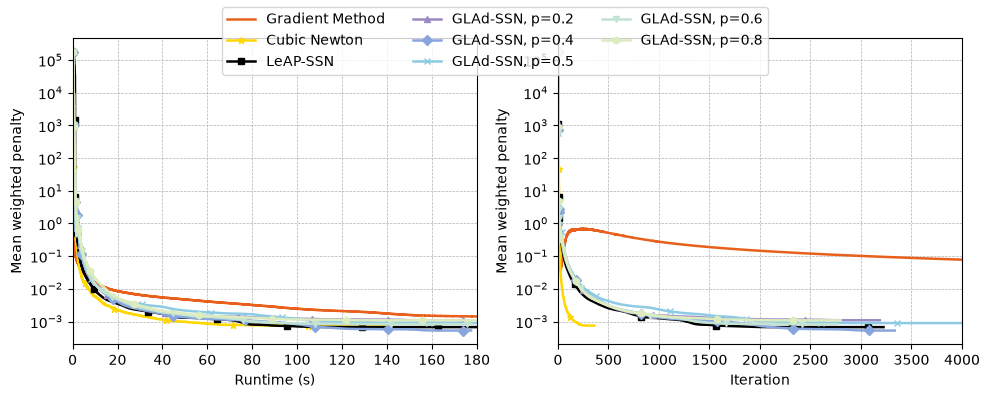

runtime: gradient target missed: Gradient Method, LeAP-SSN, GLAd-SSN, p=0.2, GLAd-SSN, p=0.4, GLAd-SSN, p=0.5, GLAd-SSN, p=0.6, GLAd-SSN, p=0.8
iteration: gradient target missed: Gradient Method, LeAP-SSN, GLAd-SSN, p=0.2, GLAd-SSN, p=0.4, GLAd-SSN, p=0.5, GLAd-SSN, p=0.6, GLAd-SSN, p=0.8


In [55]:
from utils_new import prepare_mean_histories

mean_defaults = [name for name in paper_method_order if name in completed_methods]
mean_options = {
    measure: resolve_plot_options(options, mean_defaults)
    for measure, options in mean_plot_options.items()
}
mean_marker_map = paper_marker_map
mean_marker_spacing = paper_marker_spacing
mean_gradient_target = run_metadata["configuration"]["grad_tol"]  # Display cutoff; solver unchanged.
mean_gradient_flat_tail_rtol = 1e-3  # Hide final plateaus within 0.1%; None disables.

mean_objective_zero_scale = 1e-8  # Objective residual axis only.
mean_penalty_zero_scale = 1e-8  # Penalty axis only; preserve zeros and rebounds.
mean_legend_layout = paper_legend_layout

arithmetic_mean_histories = {}
arithmetic_mean_summaries = {}
for measure in ("func", "grad_norm", "penalty"):
    prepared, summary = prepare_mean_histories(
        all_seeds_histories, mean_options[measure]["methods"], measure=measure,
        target=mean_gradient_target if measure == "grad_norm" else None,
        flat_tail_rtol=mean_gradient_flat_tail_rtol if measure == "grad_norm" else None,
    )
    arithmetic_mean_histories[measure] = prepared
    arithmetic_mean_summaries[measure] = summary

# One observed mean reference, shared by both objective panels and all methods.
mean_objective_reference = min(
    np.min(values) for summary in arithmetic_mean_summaries["func"].values()
    for values in summary["means"].values()
)
arithmetic_mean_figures = {}
mean_plot_records = {}
for measure, reference, ylabel in [
    ("func", mean_objective_reference, "Mean objective residual"),
    ("grad_norm", 0, "Mean gradient norm"),
    ("penalty", 0, "Mean weighted penalty"),
]:
    options = mean_options[measure]
    names = options["methods"]
    prepared = arithmetic_mean_histories[measure]
    summary = arithmetic_mean_summaries[measure]
    limits = {}
    for axis, limit in [("runtime", options["max_time"]), ("iteration", options["max_iter"])]:
        last_shown = max(e["x"] for e in summary[axis]["endpoints"].values())
        limits[axis] = limit if limit is not None else max(last_shown, 1e-12)
    scale = {"func": mean_objective_zero_scale, "grad_norm": 1e-14,
             "penalty": mean_penalty_zero_scale}[measure]
    fig = plot_figures(
        [prepared[name] for name in names], names,
        colors=[paper_method_colors[name.removesuffix(" (GN)")] for name in names],
        linewidths=[paper_linewidth] * len(names),
        linestyles=["--" if name.endswith(" (GN)") else "-" for name in names],
        n=experiment_config["n"], m=experiment_config["m"], mu_str=None, xlabel="Runtime (s)",
        f_star=reference, threshold=None, zero_scale=scale,
        max_time=limits["runtime"], max_iter=limits["iteration"],
        which_measure_1="runtime", which_measure_2="iteration", ylabel=ylabel,
        suptitle=None,  # The paper identifies each figure in its caption.
        sharey=True, runtime_steps=True, verbose=False, note=None,
        legend_layout=mean_legend_layout,
        marker_cycle=[mean_marker_map[name.removesuffix(" (GN)")] for name in names],
        markevery=mean_marker_spacing,
    )
    arithmetic_mean_figures[measure] = fig
    mean_plot_records[measure] = dict(
        options, reference=float(reference), zero_scale=scale, displayed_limits=limits,
        colors={name: paper_method_colors[name.removesuffix(" (GN)")] for name in names},
        linestyles={name: "--" if name.endswith(" (GN)") else "-" for name in names},
        linewidths=[paper_linewidth] * len(names),
    )
    display(fig)
    plt.close(fig)

# Keep the existing gradient results available under their previous names.
mean_gradient_histories = arithmetic_mean_histories["grad_norm"]
mean_gradient_summaries = arithmetic_mean_summaries["grad_norm"]
mean_gradient_figure = arithmetic_mean_figures["grad_norm"]
for axis, summary in mean_gradient_summaries.items():
    missed = [name for name, e in summary["endpoints"].items() if e["all_seeds_reached"] is False]
    trimmed = [name for name, e in summary["endpoints"].items() if e["flat_tail_trimmed"]]
    if missed:
        print(f"{axis}: gradient target missed:", ", ".join(missed))
    if trimmed:
        print(f"{axis}: terminal plateau hidden:", ", ".join(trimmed))

# Keep per-figure method lists/limits with their actual rendered figures.
mean_record = dict(
    format="parallel-nmf-plot-metadata", version=3,
    convention="All-seed arithmetic means with terminal values held; objective/penalty end at last recording, gradient additionally uses target/plateau cutoffs",
    objective_reference=float(mean_objective_reference),
    gradient_target=mean_gradient_target, gradient_flat_tail_rtol=mean_gradient_flat_tail_rtol,
    seeds=list(experiment_seeds), plots=mean_plot_records,
    legend_layout=mean_legend_layout, markers=mean_marker_map, marker_spacing=mean_marker_spacing,
    run_metadata=run_metadata, statuses=all_seeds_statuses,
    summaries={measure: {
        axis: dict(grid_size=len(summary["grid"]),
                   grid_start=float(summary["grid"][0]),
                   grid_end=float(summary["grid"][-1]),
                   endpoints=summary["endpoints"])
        for axis, summary in summaries.items()
    } for measure, summaries in arithmetic_mean_summaries.items()},
)


## Figure 8: gradient comparison with PALM

This is the first graphic of Figure 8: gradient norm against runtime and iteration
for Gradient Method, PALM, LeAP-SSN and GLAd-SSN p=0.5. It reuses `plot_figures`,
the shared paper style, and the same recorded per-seed histories as the other
plots. PALM is pink; GLAd-SSN p=0.5 is purple with triangle markers as in Figure 8.
Other figures keep their existing method colors/markers.

`figure8_seed_override=None` uses the representative seed selected above; an
explicit recorded seed shows an example. All four methods use that same seed.
These are actual curves, with no averaging or extension. This plot does not
change the seed-selection rule. `methods=None` includes all completed methods;
the explicit default list below selects the four Figure 8 methods. Axis limits
only zoom; set either to None for the full recorded range. Missing method runs
are reported and this optional figure is skipped until they are available.

**Save figures and data** also exports `figure8_gradient.pdf` and a compact
`figure8_gradient.json` containing the selected seed, methods, limits, styles,
solver statuses and reference to the shared `results.pkl.gz`. PALM histories,
settings and timings also participate in the usual raw snapshots and mean plots.

Paper alignment: Section 5.2 / Appendix E.2; public reference
[arXiv:2602.08069v1](https://arxiv.org/abs/2602.08069v1), with the Figure 8 layout
verified in the local manuscript revision (PDF metadata dated 2026-10-22).
The old input notebook is `experiment_matrix_factorization_alternating_gradient.ipynb`:
seed 0, (m,n,r)=(200,100,12), noise=0, alpha=.01, beta=200 in the current oracle
convention, initial factor std=.5, 3,000,000 gradient / 1,500,000 PALM / 12,000
Newton updates, initial Newton shift 1 and MINRES tolerance 1e-9. That notebook
passes no PALM stopping tolerance. This notebook retains its current settings
and uses the common `grad_tol` for PALM, so matching the layout is not an exact
reproduction of those curves. A PALM sweep contains two block updates, unlike a
full-gradient iteration. The existing PALM solver's internal recorded time starts
after its initial block spectral estimates; worker wall time includes that setup.


In [41]:
# First graphic of Figure 8. Edit this list/zoom independently of the other figures.
figure8_plot_options = dict(
    methods=["Gradient Method", "PALM", "LeAP-SSN", "GLAd-SSN, p=0.5"],
    max_time=200, max_iter=3000,
)
figure8_seed_override = None  # None uses representative_seed; otherwise a recorded seed.
figure8_zero_scale = 1e-14    # Preserve exact zeros without cutting off trajectories.


Figure 8 comparison, seed 107: Gradient Method, PALM, LeAP-SSN, GLAd-SSN, p=0.5


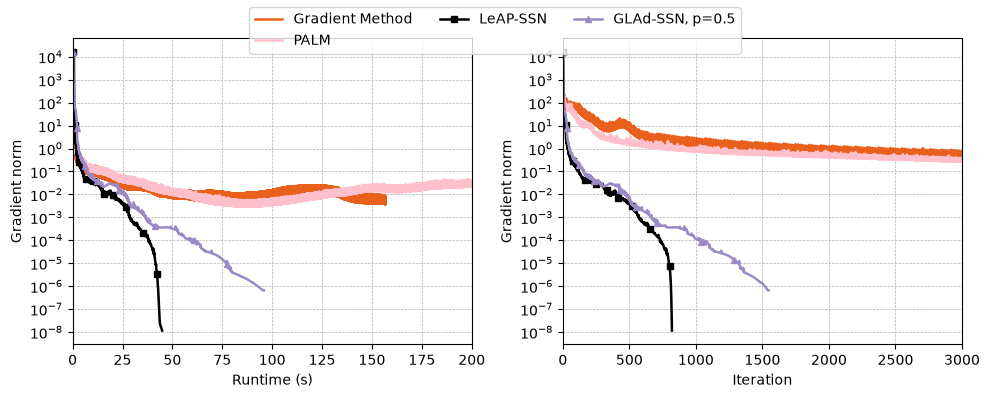

In [42]:
# Rebuild from recorded histories; clear any earlier figure if methods are missing.
figure8_figure = None
figure8_record = None
figure8_requested = figure8_plot_options["methods"]
figure8_defaults = [name for name in paper_method_order if name in completed_methods]
figure8_missing = [name for name in (figure8_requested or []) if name not in completed_methods]
if figure8_missing:
    print("Figure 8 skipped. Run these methods for all seeds, then rerun Prepare plots and this section:",
          ", ".join(figure8_missing))
else:
    figure8_options = resolve_plot_options(figure8_plot_options, figure8_defaults)
    figure8_names = figure8_options["methods"]
    figure8_seed = representative_seed if figure8_seed_override is None else int(figure8_seed_override)
    if figure8_seed not in all_seeds_histories:
        raise ValueError(f"Seed {figure8_seed} was not recorded. Available seeds: {experiment_seeds}")
    figure8_colors = dict(paper_method_colors, **{"PALM": "pink", "GLAd-SSN, p=0.5": "#9B8AC4"})
    figure8_markers = dict(paper_marker_map, **{"GLAd-SSN, p=0.5": "^"})
    figure8_styles = {
        name: dict(color=figure8_colors[name.removesuffix(" (GN)")],
                   linestyle="--" if name.endswith(" (GN)") else "-",
                   marker=figure8_markers[name.removesuffix(" (GN)")])
        for name in figure8_names
    }
    figure8_figure = plot_figures(
        [all_seeds_histories[figure8_seed][name] for name in figure8_names], figure8_names,
        colors=[figure8_styles[name]["color"] for name in figure8_names],
        linewidths=[paper_linewidth] * len(figure8_names),
        linestyles=[figure8_styles[name]["linestyle"] for name in figure8_names],
        n=experiment_config["n"], m=experiment_config["m"], mu_str=None,
        xlabel="Runtime (s)", ylabel="Gradient norm", f_star=0, threshold=None,
        zero_scale=figure8_zero_scale,
        max_time=figure8_options["max_time"], max_iter=figure8_options["max_iter"],
        which_measure_1="grad_norm", which_measure_2="grad_norm",
        suptitle=None, sharey=True, verbose=False, note=None,
        legend_layout=paper_legend_layout,
        marker_cycle=[figure8_styles[name]["marker"] for name in figure8_names],
        markevery=paper_marker_spacing,
    )
    figure8_record = dict(
        format="parallel-nmf-figure8-metadata", version=1,
        convention="Actual recorded gradient norms for one shared seed; no averaging or extension",
        seed=int(figure8_seed), seed_override=figure8_seed_override,
        representative_seed_override=(representative_seed_override if figure8_seed_override is None else None),
        seed_selection=(representative_selection if figure8_seed_override is None else None),
        **figure8_options, styles=figure8_styles, linewidths=[paper_linewidth] * len(figure8_names),
        legend_layout=paper_legend_layout, marker_spacing=paper_marker_spacing,
        zero_scale=figure8_zero_scale, threshold=None,
        statuses={name: all_seeds_statuses[figure8_seed][name] for name in figure8_names},
    )
    print(f"Figure 8 comparison, seed {figure8_seed}:", ", ".join(figure8_names))
    display(figure8_figure)
    plt.close(figure8_figure)


## Figures 3 and 8: penalty versus iteration

These two single-panel figures reuse one routine, `utils_new.plot_penalty_iterations`.
Figure 3 defaults to the eight original methods (Gradient Method, Cubic Newton,
LeAP-SSN and the five GLAd-SSN exponents). Figure 8 defaults to Gradient Method,
PALM, LeAP-SSN and GLAd-SSN p=0.5. Colors/markers follow their corresponding
comparisons above; the translucent boxed legend sits inside the upper right.

Edit each entry in `penalty_iteration_plot_options` independently:

- `methods`: explicit list in the desired order; None includes all completed methods.
- `max_iter`: iteration-axis zoom; None shows the full recorded range.
- `ylim`: penalty-axis limits, e.g. `(1e-8, 1e5)`; None uses automatic limits.
- `seed_override`: an explicit recorded seed. None uses the representative seed
  for Figure 3, and the Figure 8 gradient section's chosen seed for Figure 8.
- `zero_scale`: the linear region near zero (default `1e-10`); above this the
  axis is logarithmic. Zeros and subsequent rebounds are retained in the curves.
- `figsize`, `legend_loc`: figure size in inches and legend position.

The inputs are actual `all_seeds_histories[seed][method]["penalty"]` values,
including the initial point at iteration zero. This is the recorded weighted
nonnegativity penalty; no objective reference is subtracted. Changing axes only
zooms, and no first-hit truncation, averaging or terminal extension is applied.
The old `utils.plot_for_paper_penalty` stopped a curve at its first threshold hit;
that display rule is not used here because the penalty can later increase again.

The existing Section 5.2 / Appendix E.2 paper mapping applies (public reference
[arXiv:2602.08069v1](https://arxiv.org/abs/2602.08069v1); Figure 3 and the lower
Figure 8 panel in the local manuscript revision). Current experiment settings
are retained, so these reproduce the plot layout rather than the old numerical
curves. Missing methods skip only the affected figure. **Save figures and data**
exports `figure3_penalty.pdf`, `figure8_penalty.pdf` and their compact JSON metadata
alongside the existing figures and shared compressed raw histories.


In [43]:
# Run this options cell, then the plot cell below. No solver rerun is needed.
penalty_iteration_plot_options = {
    "figure3": dict(
        methods=["Gradient Method", "Cubic Newton", "LeAP-SSN",
                 "GLAd-SSN, p=0.2", "GLAd-SSN, p=0.4", "GLAd-SSN, p=0.5",
                 "GLAd-SSN, p=0.6", "GLAd-SSN, p=0.8"],
        max_iter=2000, ylim=None, seed_override=None,
        zero_scale=1e-10, figsize=(6, 4), legend_loc="upper right",
    ),
    "figure8": dict(
        methods=["Gradient Method", "PALM", "LeAP-SSN", "GLAd-SSN, p=0.5"],
        max_iter=2000, ylim=None, seed_override=None,
        zero_scale=1e-10, figsize=(6, 4), legend_loc="upper right",
    ),
}
# Example: zoom only Figure 3 and choose a smaller comparison.
# penalty_iteration_plot_options["figure3"]["max_iter"] = 2000
# penalty_iteration_plot_options["figure3"]["methods"] = ["Gradient Method", "LeAP-SSN", "GLAd-SSN, p=0.5"]
# penalty_iteration_plot_options["figure8"]["ylim"] = (1e-8, 1e5)


figure3 penalty, seed 107: Gradient Method, Cubic Newton, LeAP-SSN, GLAd-SSN, p=0.2, GLAd-SSN, p=0.4, GLAd-SSN, p=0.5, GLAd-SSN, p=0.6, GLAd-SSN, p=0.8


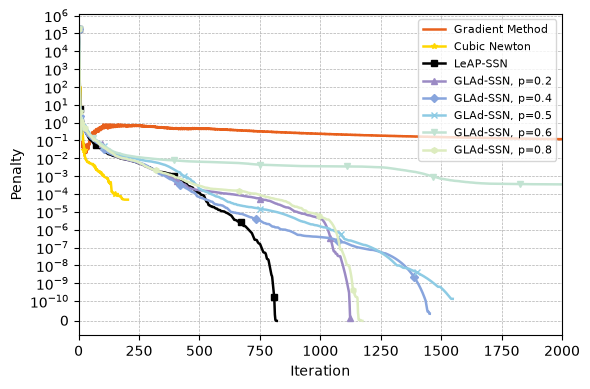

figure8 penalty, seed 107: Gradient Method, PALM, LeAP-SSN, GLAd-SSN, p=0.5


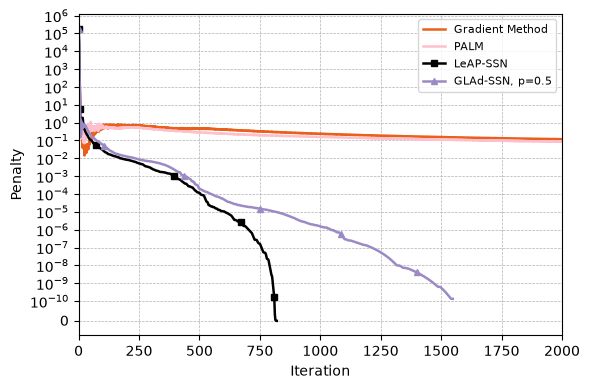

In [44]:
from utils_new import plot_penalty_iterations

# One shared routine, called once for each figure; reset to avoid stale exports.
penalty_iteration_figures = {}
penalty_iteration_records = {}
penalty_defaults = [name for name in paper_method_order if name in completed_methods]
for figure_name, options in penalty_iteration_plot_options.items():
    requested = options["methods"]
    if requested is not None and not isinstance(requested, (list, tuple)):
        raise ValueError(f"{figure_name}: methods must be a list or None.")
    missing = [name for name in (requested or []) if name not in completed_methods]
    if missing:
        print(f"{figure_name} penalty skipped; not recorded for all seeds:", ", ".join(missing))
        continue
    resolved = resolve_plot_options(
        dict(methods=requested, max_iter=options["max_iter"], max_time=None), penalty_defaults)
    names = resolved["methods"]
    inherited_override = (globals().get("figure8_seed_override") if figure_name == "figure8"
                          else None)
    default_seed = representative_seed if inherited_override is None else int(inherited_override)
    seed = default_seed if options["seed_override"] is None else int(options["seed_override"])
    if seed not in all_seeds_histories:
        raise ValueError(f"Seed {seed} was not recorded. Available seeds: {experiment_seeds}")
    colors, markers = dict(paper_method_colors), dict(paper_marker_map)
    if figure_name == "figure8":
        colors["GLAd-SSN, p=0.5"], markers["GLAd-SSN, p=0.5"] = "#9B8AC4", "^"
    styles = {
        name: dict(color=colors[name.removesuffix(" (GN)")],
                   linestyle="--" if name.endswith(" (GN)") else "-",
                   marker=markers[name.removesuffix(" (GN)")])
        for name in names
    }
    fig = plot_penalty_iterations(
        [all_seeds_histories[seed][name] for name in names], names,
        colors=[styles[name]["color"] for name in names],
        linewidths=[paper_linewidth] * len(names),
        linestyles=[styles[name]["linestyle"] for name in names],
        marker_cycle=[styles[name]["marker"] for name in names],
        markevery=paper_marker_spacing,
        max_iter=resolved["max_iter"], ylim=options["ylim"], zero_scale=options["zero_scale"],
        figsize=options["figsize"], legend_loc=options["legend_loc"],
    )
    penalty_iteration_figures[figure_name] = fig
    penalty_iteration_records[figure_name] = dict(
        format="parallel-nmf-penalty-iteration-metadata", version=1,
        figure=figure_name, measure="penalty", seed=int(seed),
        seed_override=options["seed_override"],
        inherited_figure8_seed_override=(inherited_override if options["seed_override"] is None else None),
        representative_seed_override=representative_seed_override,
        methods=names, max_iter=resolved["max_iter"], ylim=options["ylim"],
        zero_scale=options["zero_scale"], figsize=options["figsize"], legend_loc=options["legend_loc"],
        styles=styles, linewidths=[paper_linewidth] * len(names), marker_spacing=paper_marker_spacing,
        convention="Actual weighted penalty at every recorded iteration of one shared seed; zeros and rebounds retained",
        statuses={name: all_seeds_statuses[seed][name] for name in names},
    )
    print(f"{figure_name} penalty, seed {seed}:", ", ".join(names))
    display(fig)
    plt.close(fig)


## Save raw results now

Run this cell before closing the notebook or shutting down. It works directly
with the recorded results in the current kernel, independently of `SAVE_FIGURES`
and without generating plots or rerunning solvers. Wait for the saved-path message.

The new `parallel_results/raw_<timestamp>/results.pkl.gz` contains every recorded
seed/method's `func`, `grad_norm`, `penalty` and `time` arrays, plus experiment
settings, seeds, method options, statuses, timings and cubic diagnostics. Arrays
are stored losslessly with gzip compression, so you can change aggregation
and plotting routines later.
A partial collection of completed methods can also be saved. Previous snapshots
are retained. Final factors and internal state for resuming a solve are not stored.

Tomorrow, follow **Reload saved results** above. Saving the notebook alone keeps
its displayed outputs, but does not save the kernel's variables.


In [45]:
from experiment_results import save_experiment_snapshot

raw_output_dir = MF_DIR / "parallel_results" / ("raw_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
raw_results_path = save_experiment_snapshot(raw_output_dir, globals())
print("Saved raw results to", raw_results_path)
print("Use this results.pkl.gz path in 'Reload saved results' after restarting.")


Saved raw results to c:\Users\cleme\Desktop\Github Repos\skip-the-hessian-keep-the-rates\MF\parallel_results\raw_20261105_041832_684017\results.pkl.gz
Use this results.pkl.gz path in 'Reload saved results' after restarting.


## Save figures and data

Run the plotting cells from **Prepare plots**, set `SAVE_FIGURES=True`, then run
this cell. It saves three arithmetic-mean PDFs, three representative-run PDFs,
the Figure 8 gradient PDF and two penalty-versus-iteration PDFs when available,
in a new ignored
`parallel_results/<timestamp>/` folder. Each export uses a fresh folder. Rerun
just this cell to export figures already held in the kernel; no new solver runs
are needed.
It first saves `results.pkl.gz` with all raw per-seed histories and run settings,
so those results remain available even if later figure export fails.

The existing representative and arithmetic-mean PDFs include runtime and iteration panels:

| Quantity | Arithmetic mean | Representative seed |
| --- | --- | --- |
| Objective minus observed reference | `mean_objective.pdf` | `representative_objective.pdf` |
| Gradient norm | `mean_gradient.pdf` | `representative_gradient.pdf` |
| Weighted nonnegativity penalty | `mean_penalty.pdf` | `representative_penalty.pdf` |

`arithmetic_mean.json` contains display cutoffs, grid sizes/ranges, objective
reference, seeds, solver statuses, run configuration and the raw snapshot
filename. Both metadata files store the actual method list and limits for each
figure under `plots["func"]`, `plots["grad_norm"]` and `plots["penalty"]`. `representative_run.json` records the selected seed and any override,
the selection rule's inputs/scores, plotted methods, objective reference, display
settings and target/exit summaries, and points to the same raw snapshot.

Both sets of plots use the recorded `all_seeds_histories` arrays `func`,
`grad_norm`, `penalty` and `time`. For the representative run, use the saved
`seed` and `methods` to select histories from the snapshot. The full arrays are
stored only once in compressed form; JSON files contain compact metadata.
After a restart, use **Reload saved results** and rerun the plotting cells.
To recreate a customized figure, restore its saved display settings as well.

The final PALM comparison additionally saves `figure8_gradient.pdf` and
`figure8_gradient.json` if its plotting cell completed. Its metadata points to
the same compressed raw snapshot. If the selected methods have not all run, the
optional figure is skipped; the existing six figures can still be exported.
The single-panel comparisons also save `figure3_penalty.pdf` and
`figure8_penalty.pdf`, with matching JSON files recording each figure's seed,
methods, iteration/penalty limits and styles. Their data are in the same raw
snapshot. Up to nine PDFs are exported; a skipped comparison is not exported.
Earlier export folders remain untouched.

The Section 5.2 / Appendix E.2 figure mapping and paper version are recorded
at the start of this notebook. The representative selection is a supplementary
diagnostic, not a replacement for the all-seed arithmetic means. Current
experiment settings and solver behavior are unchanged.


In [56]:
if SAVE_FIGURES:
    output_dir = MF_DIR / "parallel_results" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    output_dir.mkdir(parents=True, exist_ok=False)
    from experiment_results import save_experiment_snapshot
    raw_results_path = save_experiment_snapshot(output_dir, globals())
    print("Saved raw results to", raw_results_path)
    for measure, filename in [("func", "representative_objective.pdf"),
                              ("grad_norm", "representative_gradient.pdf"),
                              ("penalty", "representative_penalty.pdf")]:
        representative_figures[measure].savefig(output_dir / filename, bbox_inches="tight")
    (output_dir / "representative_run.json").write_text(
        json.dumps(dict(representative_record, data_file=raw_results_path.name),
                   indent=2, allow_nan=False), encoding="utf-8")
    mean_output_dir = output_dir
    for measure, filename in [("func", "mean_objective.pdf"), ("grad_norm", "mean_gradient.pdf"),
                              ("penalty", "mean_penalty.pdf")]:
        arithmetic_mean_figures[measure].savefig(mean_output_dir / filename, bbox_inches="tight")
    (mean_output_dir / "arithmetic_mean.json").write_text(
        json.dumps(dict(mean_record, data_file=raw_results_path.name), indent=2, allow_nan=False), encoding="utf-8")
    figure_count = 6
    if globals().get("figure8_figure") is not None:
        figure8_figure.savefig(output_dir / "figure8_gradient.pdf", bbox_inches="tight")
        (output_dir / "figure8_gradient.json").write_text(
            json.dumps(dict(figure8_record, data_file=raw_results_path.name), indent=2, allow_nan=False),
            encoding="utf-8")
        figure_count += 1
        print("Figure 8: figure8_gradient.pdf")
    for figure_name, fig in globals().get("penalty_iteration_figures", {}).items():
        filename = f"{figure_name}_penalty"
        fig.savefig(output_dir / f"{filename}.pdf", bbox_inches="tight")
        (output_dir / f"{filename}.json").write_text(
            json.dumps(dict(penalty_iteration_records[figure_name], data_file=raw_results_path.name),
                       indent=2, allow_nan=False), encoding="utf-8")
        figure_count += 1
        print("Penalty versus iteration:", f"{filename}.pdf")
    print(f"Saved {figure_count} figures, compressed raw results and plot metadata to", output_dir)
    print("Arithmetic means: mean_objective.pdf, mean_gradient.pdf, mean_penalty.pdf")
    print(f"{representative_record['label']} seed {representative_record['seed']}: "
          "representative_objective.pdf, representative_gradient.pdf, representative_penalty.pdf")
else:
    print("Set SAVE_FIGURES=True, then rerun this cell to export the figures and their data (including the Figure 3/8 comparisons when plotted).")


Saved raw results to c:\Users\cleme\Desktop\Github Repos\skip-the-hessian-keep-the-rates\MF\parallel_results\20261105_051152_877484\results.pkl.gz
Figure 8: figure8_gradient.pdf
Penalty versus iteration: figure3_penalty.pdf
Penalty versus iteration: figure8_penalty.pdf
Saved 9 figures, compressed raw results and plot metadata to c:\Users\cleme\Desktop\Github Repos\skip-the-hessian-keep-the-rates\MF\parallel_results\20261105_051152_877484
Arithmetic means: mean_objective.pdf, mean_gradient.pdf, mean_penalty.pdf
Representative seed 107: representative_objective.pdf, representative_gradient.pdf, representative_penalty.pdf
